# E56: Does neuron patching tell a half-known word map from a cipher, where the decomposition does?

## The answer

No. Neuron patching does not tell whether a fine-tune strengthens what the model half-knows or teaches it something new. The decomposition still does, now at five seeds. Sixteen neurons carry nothing for either kind. All the neurons together carry almost all of the half-known map's gain and about seventy percent of the cipher's at equal size. That gap follows how spread out the cipher's early update is: trained further, the cipher looks like the half-known map. Our neuron prediction passed only because we merged those counts before running.

## What we were trying to test

The project asks whether a VPD decomposition can tell a fine-tune that strengthens something the original model already does from one that teaches it something new. The previous experiment built a pair for this on the small model. Each window is Pile text with a rare marker token, then a key word; the model must predict the key's value next. Both tasks use the same 32 keys and the same windows.

- **Elicit map.** Each key's value is a word the original model already ranks 2nd to 20th there.
- **Cipher.** The same keys mapped to words the original model almost never predicts there.

The decomposition separated the two and one mean steering vector did not. Two objections remained. One mean vector is the same for every key, so a key-dependent map defeats it by construction; a cheap reader that depends on the input might do better. And the margin rested on two seeds.

So this experiment tries **neuron patching**, a cheap reader that depends on the input. Rank the 12288 MLP neurons by how far the fine-tune moved their mean activation at the answer position. Give the top k of them the fine-tuned model's activations inside an original-model forward. Read what share of the fine-tune's gain in log P of the target this recovers, on windows not used for the ranking. It also adds seeds 2 to 4 of both fine-tunes.

The elicit map is read at step 10, when it has learned the table. The cipher learns more slowly, so it is read at step 9, where its weight change has the same size. It is also read at its own scored step 30, when it has fully learned. Every share reads 0 for the original model and 1 for the fine-tuned model.

- **Re-gating share** $r$: keep every subcomponent at its original weights and let only the causal-importance function Γ see the fine-tuned model's activations. The share of the fine-tune's log-odds gain this recovers is $r$. High $r$ means the fine-tune works by switching existing subcomponents on.
- **Steering share**: add to the original model the mean difference between the fine-tuned and original residual streams at the answer position, and read its share of the same log-odds gain.

A pair separates when the gap between the two kinds' means beats the larger range between seeds and is at least 0.2.

## What we expected, and why

- **Neuron patching does not separate the pair.** On the earlier copy and cipher pair, the top sixteen neurons carried about nothing and half the gain needed every neuron. We expected the same here: both kinds need over 1000 neurons, with no difference.
- **At five seeds the decomposition still separates the pair and steering does not.** The decomposition's gap should be at least three times steering's gap plus steering's seed range.
- **The cipher's re-gating share barely moves between step 9 and step 30,** by under 0.1, as on the first two seeds.

Before any patch was scored, the job re-read the six saved weight changes. Every earlier reading reproduced to the last digit. Giving every neuron its own original value moved nothing. Patching block 3's whole residual stream recovered all of every gain.

## Does neuron patching tell the half-known map from the cipher?

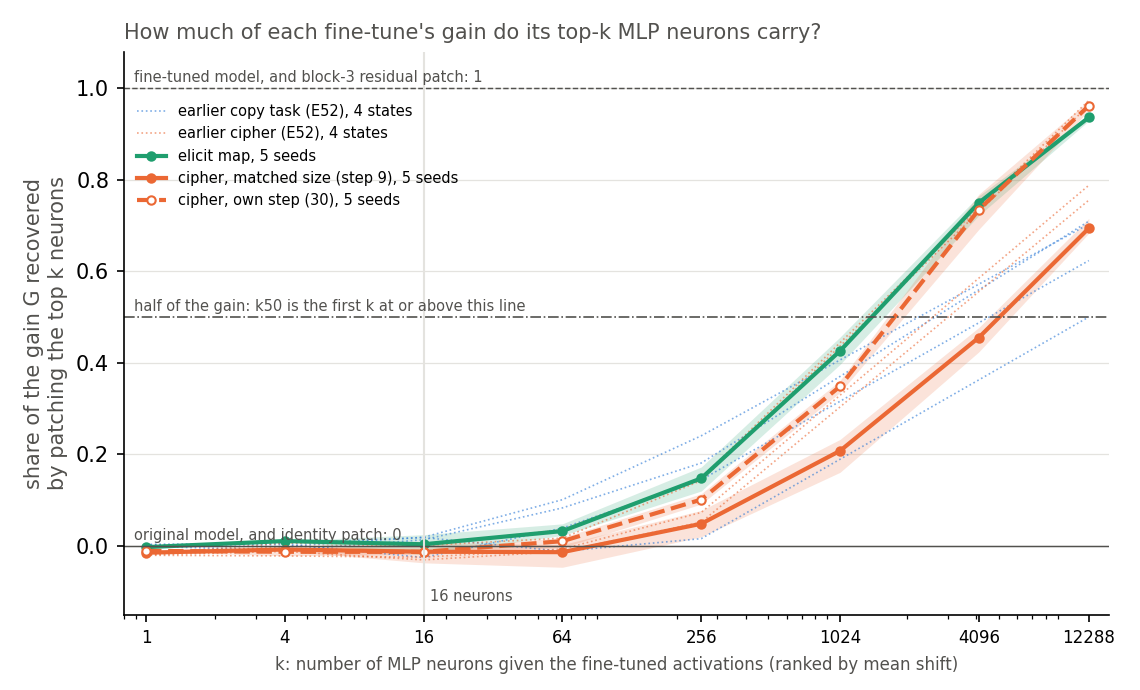

In [1]:
from pathlib import Path
from IPython.display import Image, display
FIG = Path("../experiments/keydependent_patch/figures")
display(Image(filename=str(FIG / "b2_curves.png")))

**Reading it.** Not as a reader of kind. On the left, sixteen neurons carry nothing for either task: every value sits within 0.04 of zero. On the right the curves part. With all neurons patched, the elicit map recovers 0.93 to 0.94 of its gain. The cipher at matched size recovers 0.68 to 0.72. The seed bands do not overlap.

The dashed orange curve is why we do not read that as kind. Trained on to step 30, the cipher's curve lies on the elicit map's, while its re-gating share does not move. The dotted lines are the earlier copy and cipher pair, where all neurons carried more of the cipher's gain than of the copy task's: the other way round. Patching the whole residual stream recovers every gain, so the missing part travels through attention. At step 9 that is about 30% of the cipher's gain; at step 30 about 4%. What the curve reads is how much of the gain sits in MLP neurons at that checkpoint.

### The prediction passed only because the counts were merged before the run

One of the two filed numbers is the neurons needed for half the gain. The elicit map needs 4096 on all five seeds and the matched cipher 12288 on all five. With no spread between seeds, that one step on the grid clears the separation rule. **On the rule as first filed, the prediction fails**, and it would have stopped the experiment after the first two seeds.

A code review caught this before any job ran. A dated amendment then merged every count over 1000 into one bin, matching the outcome the plan had filed in advance: over 1000 on all states, no separation. Under that merge the prediction passes.

We keep the merged verdict, for three reasons from the reading we adopted, Fable's advice in `reports/reviews/2026-10-30_review_e56-k50-fable-advice.md`. The cipher at its own step reads the elicit curve while its re-gating share stays near 0.25. The earlier pair reads the full-width share the other way round. And a state with the elicit map's curve and the cipher's re-gating share shows the curve cannot explain the decomposition's separation.

So the headline is narrowed by one phrase. Neuron patching at matched size does tell the two states apart, by how spread out the early cipher update is. It does not tell them apart by which neurons carry the gain or how few do. And the difference is gone at the cipher's own step and reversed on the earlier pair.

## At five seeds, does the decomposition still separate the pair where steering does not?

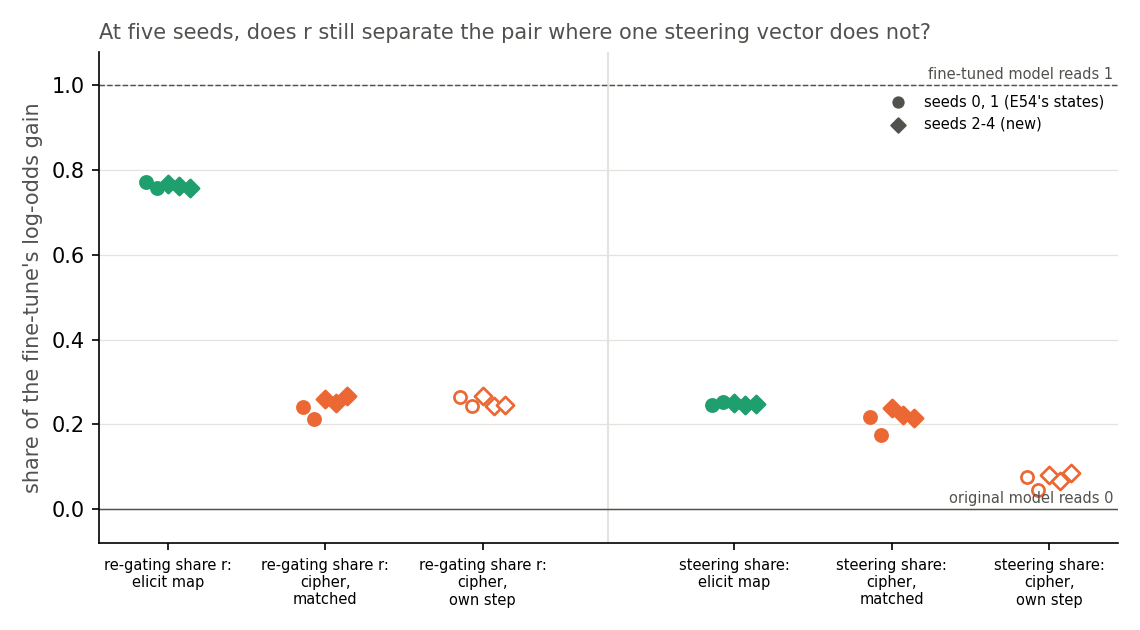

In [2]:
display(Image(filename=str(FIG / "p2_shares.png")))

**Reading it.** Yes. Switching existing subcomponents on recovers 0.76 to 0.77 of the elicit map's gain on all five seeds, and 0.21 to 0.27 of the matched cipher's. The gap is 0.52, nearly ten times the larger seed range. One steering vector recovers about 0.25 of the elicit map's gain and 0.18 to 0.24 of the matched cipher's. Its gap of 0.03 is under its own seed range, so steering does not separate the pair. The new seeds, drawn as diamonds, fall among the first two. On the cautious filed ratio, the decomposition's gap is 5.2 times steering's gap plus its range, above the bar of 3.

## Does the cipher's re-gating share depend on where it was stopped?

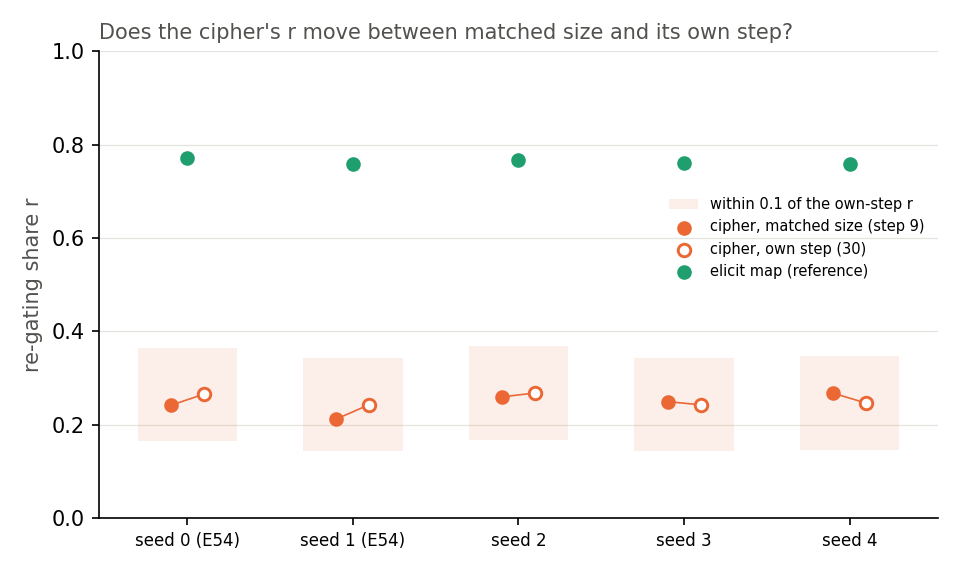

In [3]:
display(Image(filename=str(FIG / "p3_size.png")))

**Reading it.** No. From step 9 to step 30 the cipher's weight change nearly doubles. On the five seeds its re-gating share moves by 0.007 to 0.031, well inside the shaded band of 0.1. The neuron-patch curve and the steering share both move over the same steps; the re-gating share does not.

## What we learned

The decomposition's reading of this pair now holds over five seeds and keeps its margin over steering. An input-dependent cheap reader, neuron patching, does not reproduce it. Neuron patching does see a difference at matched size, but that difference tracks how far the cipher has trained and flips on the earlier pair. So the claim that the route split reads whether an update strengthens what the model half-knows, where cheap activation baselines do not, survives with one phrase narrowed. It rests on one pair, one small model, and a behavioural label of "half-known".

## How compelling is the evidence

Five seeds per kind, one pair of tasks, one 67M model. Neuron patching sees only MLP neurons, not attention, and ranks them by mean shift, so neurons that matter per key but cancel on average rank low. The neuron count's resolution is the grid, on which 4096 and 12288 are neighbours. The re-gating share is blind to which subcomponents switch on; a new circuit built from existing subcomponents also reads as elicited. The "half-known" label is the original model's probability of each value, not a readout of its internal representation.

## Surprises

- **The neuron counts differ by kind at matched size.** We expected no difference; the elicit map needs 4096 and the matched cipher 12288 on every seed. As first filed, this would have failed the prediction and stopped the experiment.
- **The cipher's update moves into the MLP neurons as it trains,** while its re-gating share stays put.

## What next

- **A readout check on the elicit keys,** after Jain et al.: read each key's value linearly from the original model and test it causally. If it fails on many keys, the "half-known" label needs rebuilding.
- **Neuron patching on Qwen,** if that line runs it, filed with the expectation that no separation holds at both steps. One that holds at both steps and on both pairs would overturn the reading above.

## Scorecard

| id | claim | read | verdict |
|---|---|---|---|
| stage 0 | saved states, patch path and earlier readings reproduce | identity patch ≤ 9.5e-8; residual patch 1 within 6e-8; full width moves 13-17 nats; differences 0 | pass |
| P1 | neuron patching does not separate the pair | N16 gap 0.016 under range 0.045; k50 4096 elicit vs 12288 cipher, merged into one bin | **pass under the pre-run merge; fails as first filed** |
| P2 | r separates, steering does not, ratio ≥ 3 | r gap 0.518; S_lo gap 0.034 under range 0.065; ratio 5.22 | pass |
| P3 | cipher r within 0.1 of its own-step r, seeds 2-4 | 0.008, 0.007, 0.021 | pass |

Full tables, rules and departures from the literature: `reports/analyses/2026-10-30_analysis_e56-keydependent-patch.md`.

## Not run

- The readout and causal check on the elicit keys.
- A finer grid of k, patching within one block, or attention-head patching.
- Neuron ranking per key.
- A random update of matched size as a null.
- Any per-key breakdown, and any of this on Qwen.

## Provenance

MATS cluster L40, debug queue, $0. Job 46170 read the six saved states; job 46171 trained and read seeds 2 to 4. Results `experiments/keydependent_patch/results/job1.json`, `job2.json`; rules `predictions.json`; figures from `experiments/keydependent_patch/plot.py`.